# STEP 1: Install Required Libraries


In [10]:
!pip install librosa soundfile numpy scikit-learn


Defaulting to user installation because normal site-packages is not writeable


# 📂 Data Handling


In [11]:
import os
#from pydub import AudioSegment  # optional for conversion
from IPython.display import Audio

# Define path
data_dir = r"C:\Users\lenovo\Desktop\project-1\data_set_from kaggle"  # structured with /depressed and /normal

# Confirm structure
depressed = os.listdir(f"{data_dir}/depression1")
normal = os.listdir(f"{data_dir}/normal1")

print(f"Found {len(depressed)} depressed and {len(normal)} normal files.")


Found 400 depressed and 400 normal files.


# ***DATA VISUALIZATION***




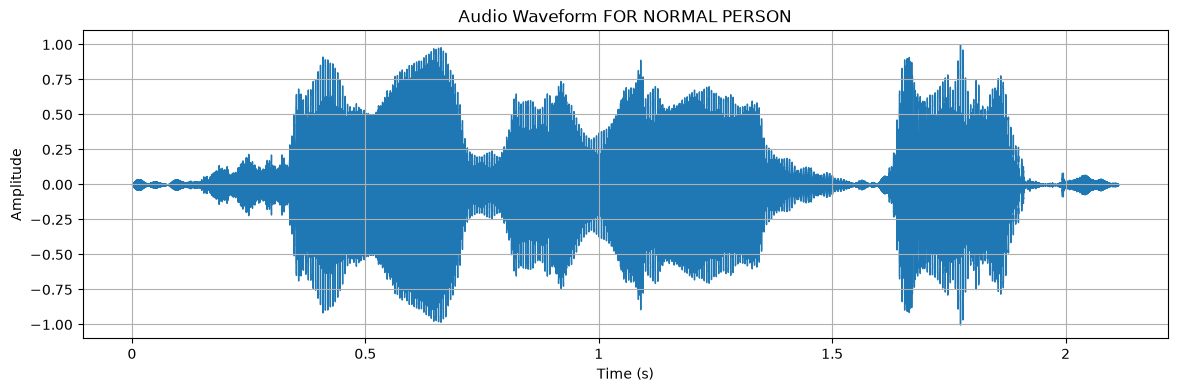

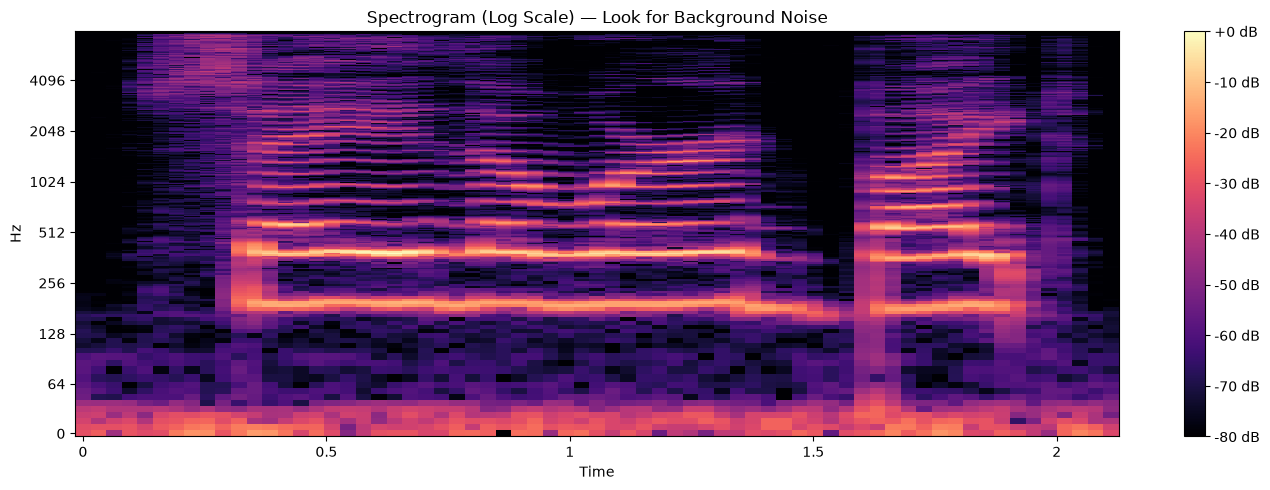

In [12]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

def visualize_audio_noise(path, sr=16000):
    # Load the audio
    y, _ = librosa.load(path, sr=sr)

    # Normalize (optional for cleaner plot)
    y = y / np.max(np.abs(y))

    # Plot waveform
    plt.figure(figsize=(14, 4))
    librosa.display.waveshow(y, sr=sr)
    plt.title('Audio Waveform FOR NORMAL PERSON')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.show()

    # Plot log-scaled spectrogram (reveals background noise well)
    D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    plt.figure(figsize=(14, 5))
    librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='log', cmap='magma')
    plt.colorbar(format='%+2.0f dB')
    plt.title('Spectrogram (Log Scale) — Look for Background Noise')
    plt.tight_layout()
    plt.show()

# Example usage
# visualize_audio_noise('/content/drive/MyDrive/wav_files/normal/normal_001.wav')
visualize_audio_noise('C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\normal1\\OA_bite_neutral.wav')



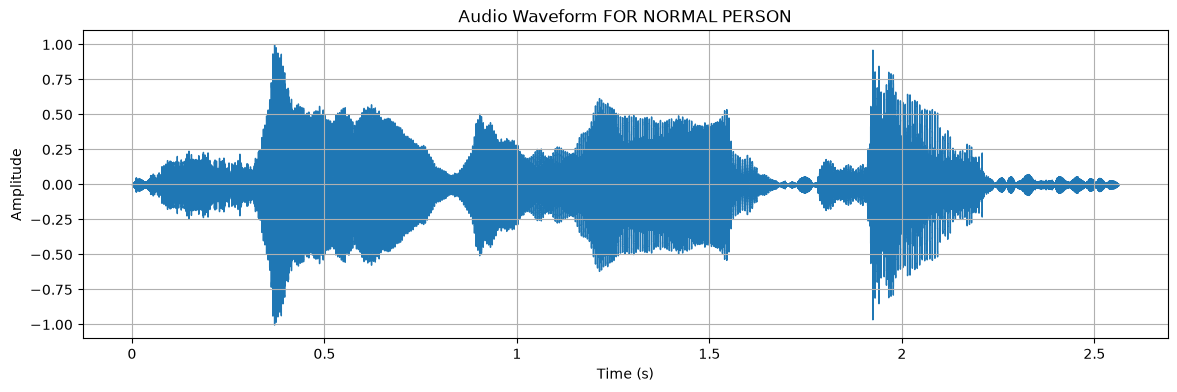

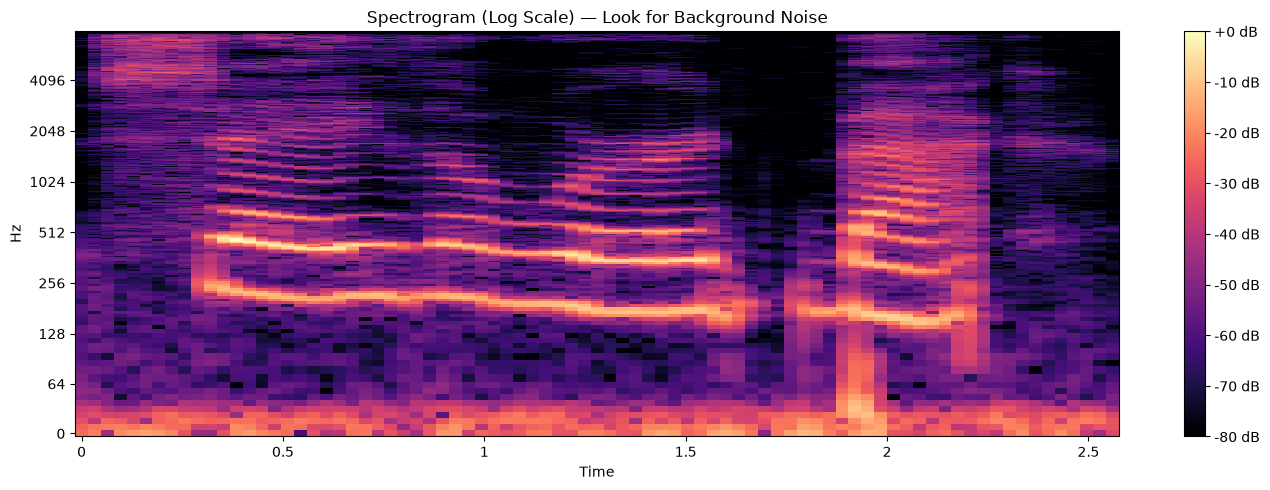

In [13]:

# Example usage
visualize_audio_noise('C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\depression1\\OAF_back_sad.wav')


# 🎧 Preprocessing: Audio ***Cleaning***

In [14]:
import librosa
import numpy as np
import os

def preprocess_audio(path, sr=16000):
    y, _ = librosa.load(path, sr=sr)
    y = y / np.max(np.abs(y))  # normalize amplitude
    y = librosa.effects.preemphasis(y)  # pre-emphasis filter
    y = librosa.effects.trim(y, top_db=20)[0]  # silence removal
    return y



In [15]:
folder_paths = {
    'depressed': r'C:\Users\lenovo\Desktop\project-1\data_set_from kaggle\depression1',
    'normal': r'C:\Users\lenovo\Desktop\project-1\data_set_from kaggle\normal1'
}

# Lists to store processed data and labels
all_processed_audios = []
all_file_labels = []

target_sr = 16000

# Loop through folders and preprocess files
for label, folder_path in folder_paths.items():
    print(f"\nProcessing {label.upper()} folder: {folder_path}")

    filenames = [f for f in os.listdir(folder_path) if f.endswith('.wav')]
    filenames.sort()  # Optional: sort for consistent order

    for i, filename in enumerate(filenames):
        file_path = os.path.join(folder_path, filename)
        try:
            processed_audio = preprocess_audio(file_path, sr=target_sr)
            if processed_audio.size > 0:
                all_processed_audios.append(processed_audio)
                all_file_labels.append(label)
            else:
                print(f"Skipped empty: {filename}")
        except Exception as e:
            print(f"Error processing {filename}: {e}")



print("\n✅ Preprocessing Complete")
print(f"Total files processed: {len(all_processed_audios)}")
print(f"Labels distribution: {dict((l, all_file_labels.count(l)) for l in set(all_file_labels))}")



Processing DEPRESSED folder: C:\Users\lenovo\Desktop\project-1\data_set_from kaggle\depression1

Processing NORMAL folder: C:\Users\lenovo\Desktop\project-1\data_set_from kaggle\normal1

✅ Preprocessing Complete
Total files processed: 800
Labels distribution: {'depressed': 400, 'normal': 400}


# DATA VISUALIZATION BEFORE AND AFTER PREPROCESSING

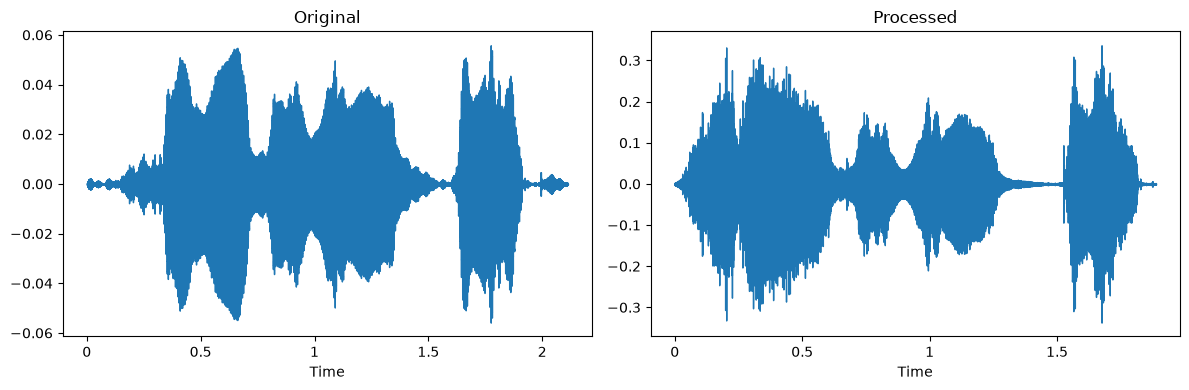

In [16]:
import matplotlib.pyplot as plt
path="C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\normal1\\OA_bite_neutral.wav"
original, _ = librosa.load(path, sr=16000)
processed = preprocess_audio(path)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
librosa.display.waveshow(original, sr=16000)
plt.title('Original')

plt.subplot(1, 2, 2)
librosa.display.waveshow(processed, sr=16000)
plt.title('Processed')
plt.tight_layout()
plt.show()


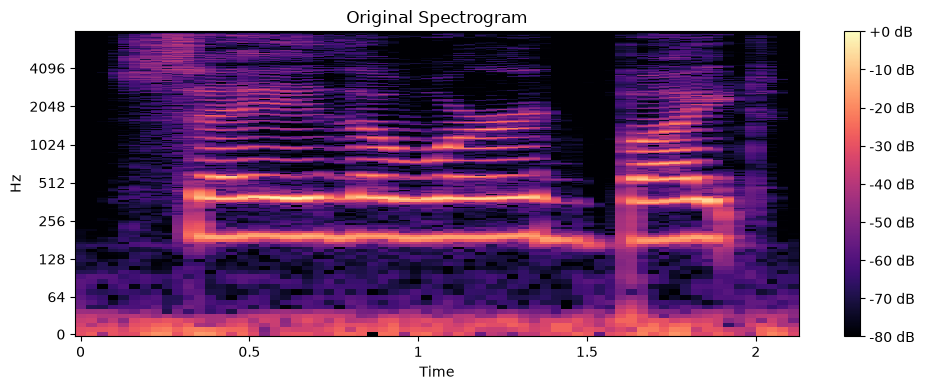

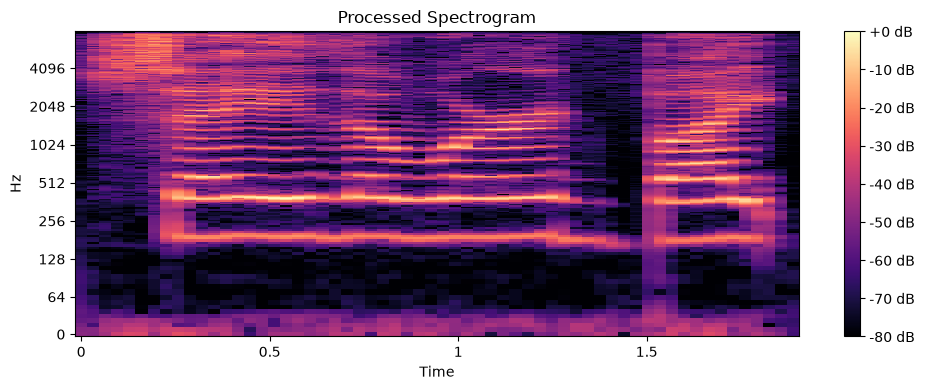

In [17]:
import librosa.display

def plot_spectrogram(y, sr, title):
    D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='log')
    plt.colorbar(format='%+2.0f dB')
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_spectrogram(original, 16000, "Original Spectrogram")
plot_spectrogram(processed, 16000, "Processed Spectrogram")


# 📊 Feature Extraction

In [18]:
def extract_features(path):
    y = preprocess_audio(path)
    sr = 16000

    # MFCC
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    mfcc_mean = np.mean(mfccs.T, axis=0)

    # Pitch
    pitches, mags = librosa.piptrack(y=y, sr=sr)
    pitch = [pitches[mags[:, i].argmax(), i] for i in range(pitches.shape[1])]
    pitch_mean = np.mean([p for p in pitch if p > 0]) if pitch else 0

    # Energy
    energy = np.mean(librosa.feature.rms(y=y))

    # Zero-Crossing Rate
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))

    # Combine features
    return np.hstack([mfcc_mean, pitch_mean, energy, zcr])





#***visuals for mfcc for nomal person***
  



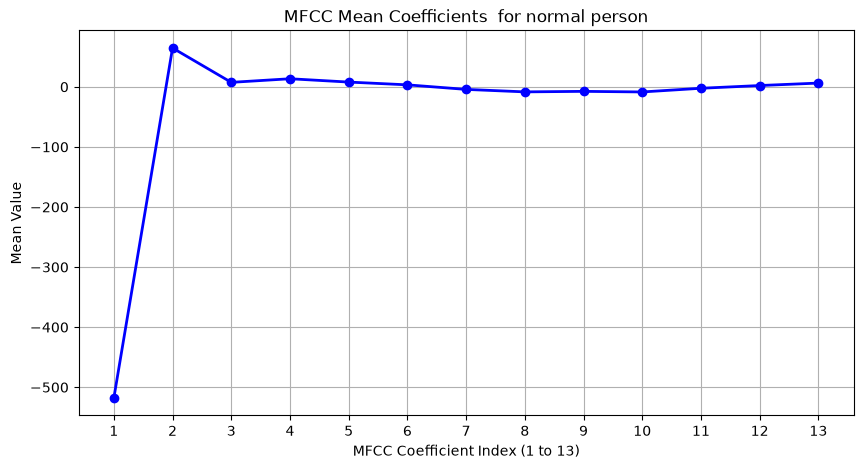

In [19]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Load your audio file
file_path = 'C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\normal1\\OA_bite_neutral.wav'  # 🔁 Replace with your file path
y, sr = librosa.load(file_path, sr=16000)

# Extract MFCC features
mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

# Calculate the mean of each MFCC coefficient over time
mfcc_mean = np.mean(mfcc, axis=1)

# Plot the mean MFCC values
plt.figure(figsize=(10, 5))
plt.plot(range(1, 14), mfcc_mean, marker='o', color='blue', linewidth=2)
plt.title("MFCC Mean Coefficients  for normal person")
plt.xlabel("MFCC Coefficient Index (1 to 13)")
plt.ylabel("Mean Value")
plt.grid(True)
plt.xticks(np.arange(1, 14, 1))
plt.show()


# ***visuals for mfcc for depressed person***

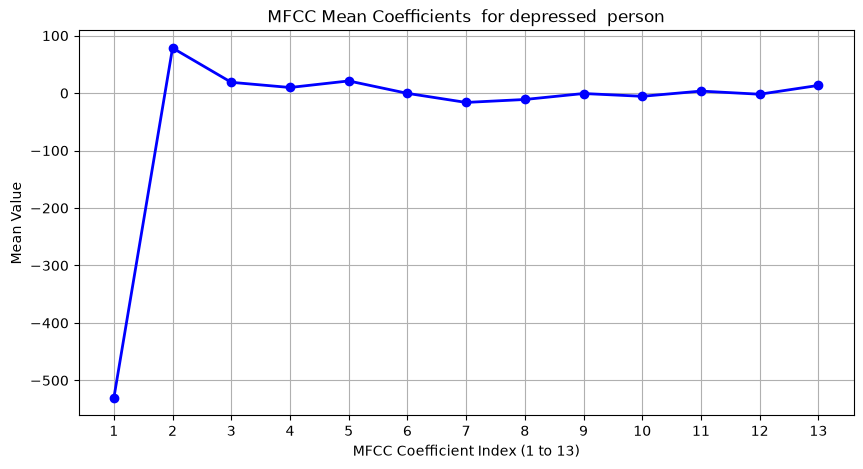

In [20]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Load your audio file
file_path = 'C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\depression1\\OAF_back_sad.wav'  # 🔁 Replace with your file path
y, sr = librosa.load(file_path, sr=16000)

# Extract MFCC features
mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

# Calculate the mean of each MFCC coefficient over time
mfcc_mean = np.mean(mfcc, axis=1)

# Plot the mean MFCC values
plt.figure(figsize=(10, 5))
plt.plot(range(1, 14), mfcc_mean, marker='o', color='blue', linewidth=2)
plt.title("MFCC Mean Coefficients  for depressed  person")
plt.xlabel("MFCC Coefficient Index (1 to 13)")
plt.ylabel("Mean Value")
plt.grid(True)
plt.xticks(np.arange(1, 14, 1))
plt.show()

# ***pitch representation for normal person voice***

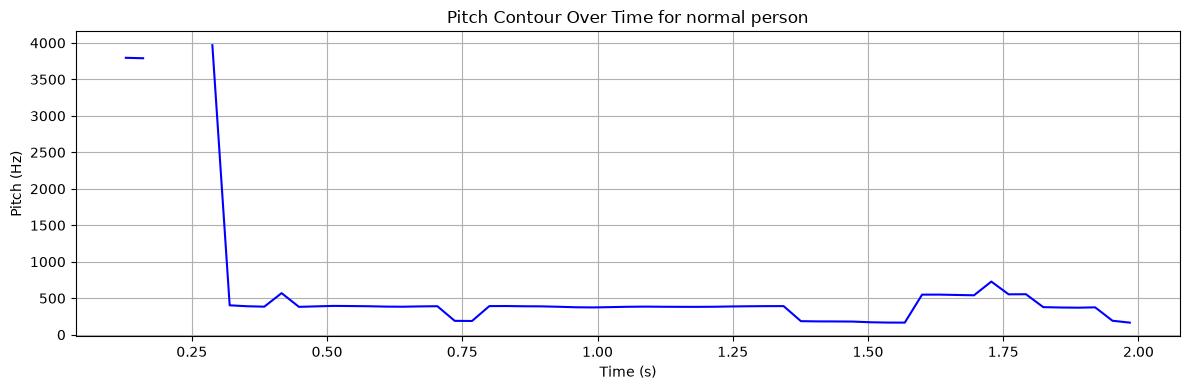

In [21]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

def visualize_pitch(audio_path):
    y, sr = librosa.load(audio_path, sr=16000)  # Load audio file
    pitches, magnitudes = librosa.piptrack(y=y, sr=sr)

    # Extract the most prominent pitch at each frame
    pitch_values = []
    for i in range(pitches.shape[1]):
        index = magnitudes[:, i].argmax()
        pitch = pitches[index, i]
        pitch_values.append(pitch if pitch > 0 else np.nan)  # Ignore 0s

    # Create time axis
    frames = range(len(pitch_values))
    times = librosa.frames_to_time(frames, sr=sr)

    # Plot pitch over time
    plt.figure(figsize=(12, 4))
    plt.plot(times, pitch_values, color='b')
    plt.xlabel("Time (s)")
    plt.ylabel("Pitch (Hz)")
    plt.title("Pitch Contour Over Time for normal person")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Example usage
visualize_pitch("C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\normal1\\OA_bite_neutral.wav")

***METHODS FOR VISUALIZING EXTRACTED FEATURES***

# ***pitch representation for depressed person **


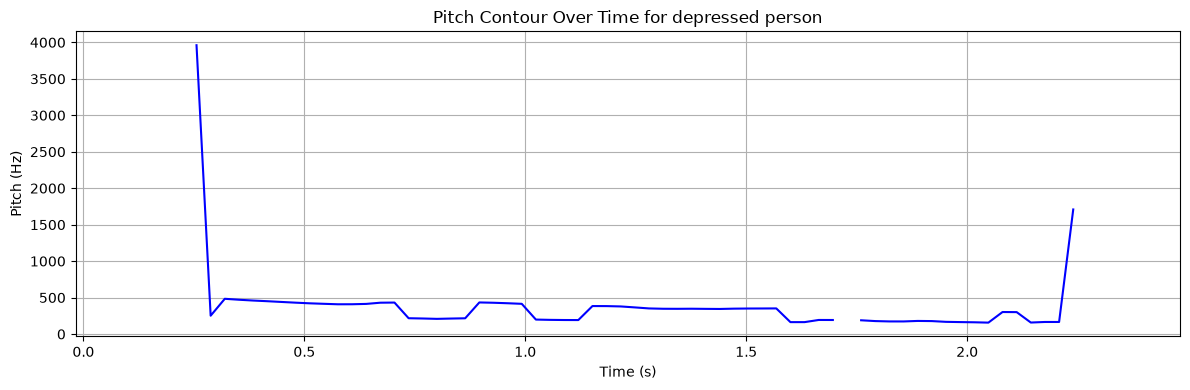

In [22]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

def visualize_pitch(audio_path):
    y, sr = librosa.load(audio_path, sr=16000)  # Load audio file
    pitches, magnitudes = librosa.piptrack(y=y, sr=sr)

    # Extract the most prominent pitch at each frame
    pitch_values = []
    for i in range(pitches.shape[1]):
        index = magnitudes[:, i].argmax()
        pitch = pitches[index, i]
        pitch_values.append(pitch if pitch > 0 else np.nan)  # Ignore 0s

    # Create time axis
    frames = range(len(pitch_values))
    times = librosa.frames_to_time(frames, sr=sr)

    # Plot pitch over time
    plt.figure(figsize=(12, 4))
    plt.plot(times, pitch_values, color='b')
    plt.xlabel("Time (s)")
    plt.ylabel("Pitch (Hz)")
    plt.title("Pitch Contour Over Time for depressed person")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Example usage
visualize_pitch("C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\depression1\\OAF_back_sad.wav")

# ***zero cross rate for normal person***

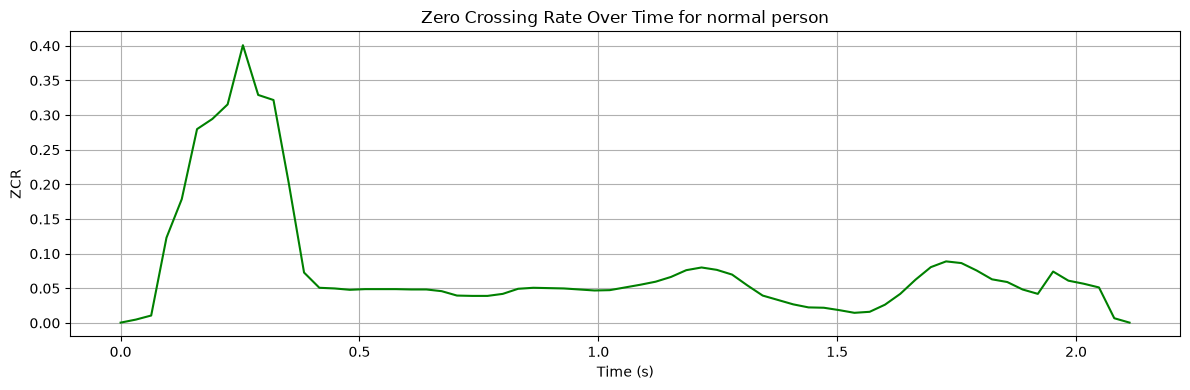

In [23]:
def visualize_zcr(audio_path):
    y, sr = librosa.load(audio_path, sr=16000)
    frame_length = 2048
    hop_length = 512

    zcr = librosa.feature.zero_crossing_rate(y, frame_length=frame_length, hop_length=hop_length)[0]
    times = librosa.frames_to_time(np.arange(len(zcr)), sr=sr, hop_length=hop_length)

    plt.figure(figsize=(12, 4))
    plt.plot(times, zcr, color='g')
    plt.xlabel("Time (s)")
    plt.ylabel("ZCR")
    plt.title("Zero Crossing Rate Over Time for normal person")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Example usage
visualize_zcr("C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\normal1\\OA_bite_neutral.wav")

# ***zero cross rate for depressed person person***

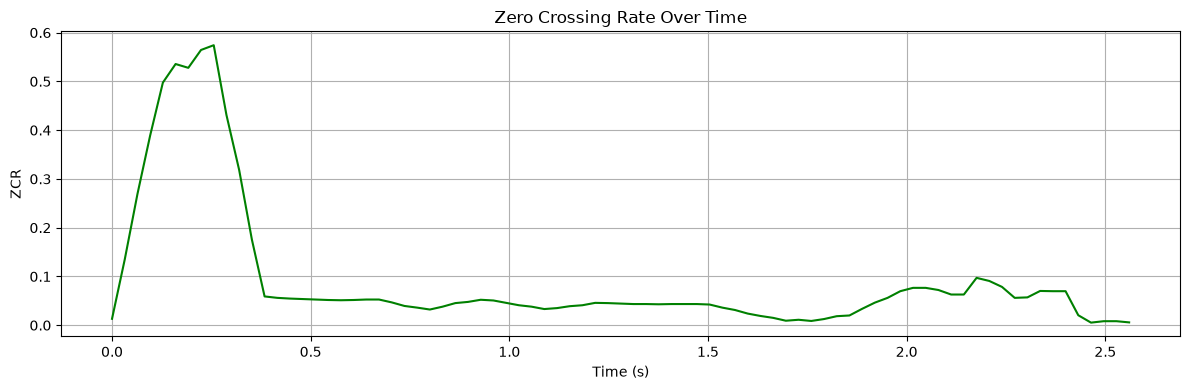

In [24]:
def visualize_zcr(audio_path):
    y, sr = librosa.load(audio_path, sr=16000)
    frame_length = 2048
    hop_length = 512

    zcr = librosa.feature.zero_crossing_rate(y, frame_length=frame_length, hop_length=hop_length)[0]
    times = librosa.frames_to_time(np.arange(len(zcr)), sr=sr, hop_length=hop_length)

    plt.figure(figsize=(12, 4))
    plt.plot(times, zcr, color='g')
    plt.xlabel("Time (s)")
    plt.ylabel("ZCR")
    plt.title("Zero Crossing Rate Over Time")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Example usage
visualize_zcr("C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\depression1\\OAF_back_sad.wav")

# ***ENERGY LEVEL FOR DEPRESSED PERSON***

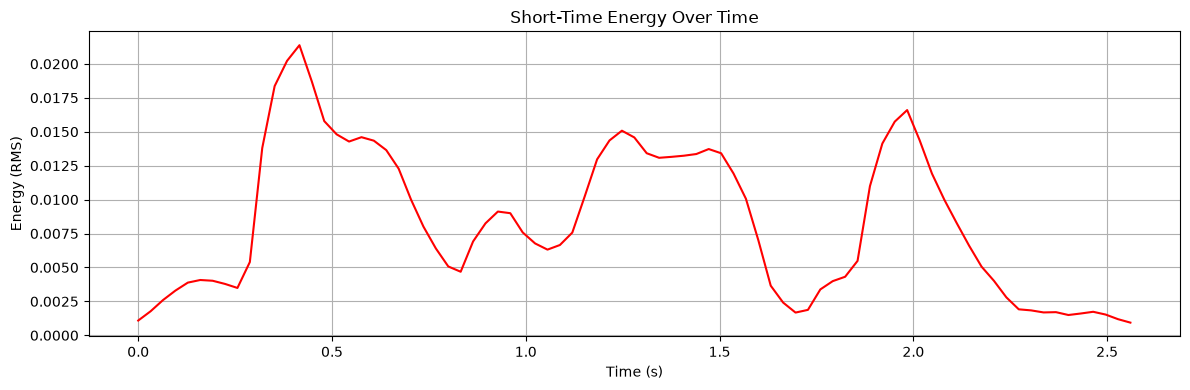

In [25]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

def visualize_energy(audio_path):
    # Load audio file
    y, sr = librosa.load(audio_path, sr=16000)

    # Frame and hop length (typical settings)
    frame_length = 2048
    hop_length = 512

    # Compute RMS (Root Mean Square) Energy
    energy = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)[0]

    # Time axis for plotting
    frames = np.arange(len(energy))
    times = librosa.frames_to_time(frames, sr=sr, hop_length=hop_length)

    # Plot energy over time
    plt.figure(figsize=(12, 4))
    plt.plot(times, energy, color='red')
    plt.xlabel("Time (s)")
    plt.ylabel("Energy (RMS)")
    plt.title("Short-Time Energy Over Time")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Example usage
visualize_energy("C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\depression1\\OAF_back_sad.wav")

# ***ENERGY LEVEL FOR NORMAL PERSON***

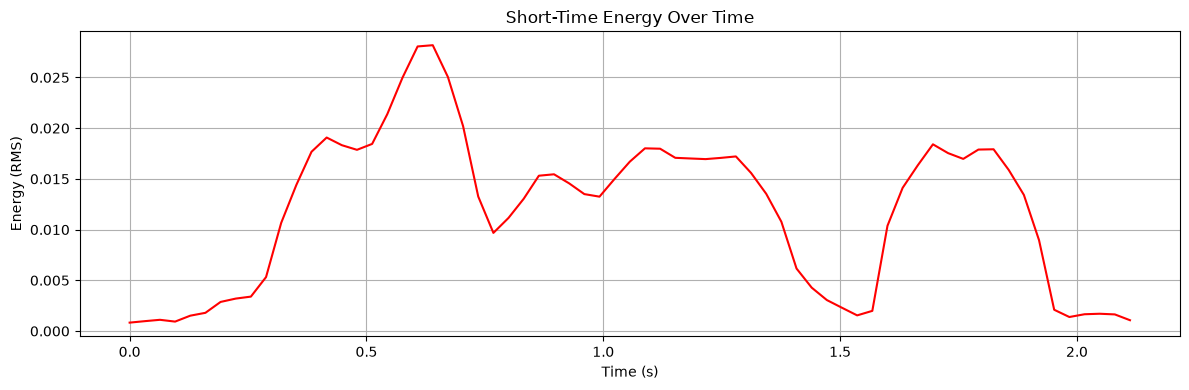

In [26]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

def visualize_energy(audio_path):
    # Load audio file
    y, sr = librosa.load(audio_path, sr=16000)

    # Frame and hop length (typical settings)
    frame_length = 2048
    hop_length = 512

    # Compute RMS (Root Mean Square) Energy
    energy = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)[0]

    # Time axis for plotting
    frames = np.arange(len(energy))
    times = librosa.frames_to_time(frames, sr=sr, hop_length=hop_length)

    # Plot energy over time
    plt.figure(figsize=(12, 4))
    plt.plot(times, energy, color='red')
    plt.xlabel("Time (s)")
    plt.ylabel("Energy (RMS)")
    plt.title("Short-Time Energy Over Time")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Example usage
visualize_energy("C:\\Users\\lenovo\\Desktop\\project-1\\data_set_from kaggle\\normal1\\OA_bite_neutral.wav")

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Example: visualize 10 samples from your extracted feature set
def visualize_extracted_features(X, y, class_names=["normal", "depressed"]):
    X = np.array(X)
    y = np.array(y)

    num_features = X.shape[1]
    num_samples = min(10, len(X))  # Limit to 10 samples

    plt.figure(figsize=(12, 6))

    for i in range(num_samples):
        plt.plot(X[i], label=f'{class_names[y[i]]} #{i+1}')

    plt.title('Extracted Feature Vectors (MFCCs + Pitch + Energy + ZCR)')
    plt.xlabel('Feature Index')
    plt.ylabel('Feature Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


🏷️ Dataset *Creation*

In [28]:
X, y = [], []
for label, folder in enumerate(["normal1", "depression1"]):
    folder_path = f"{data_dir}/{folder}"
    for file in os.listdir(folder_path):
        if file.endswith(".wav"):
            features = extract_features(os.path.join(folder_path, file))
            X.append(features)
            y.append(label)




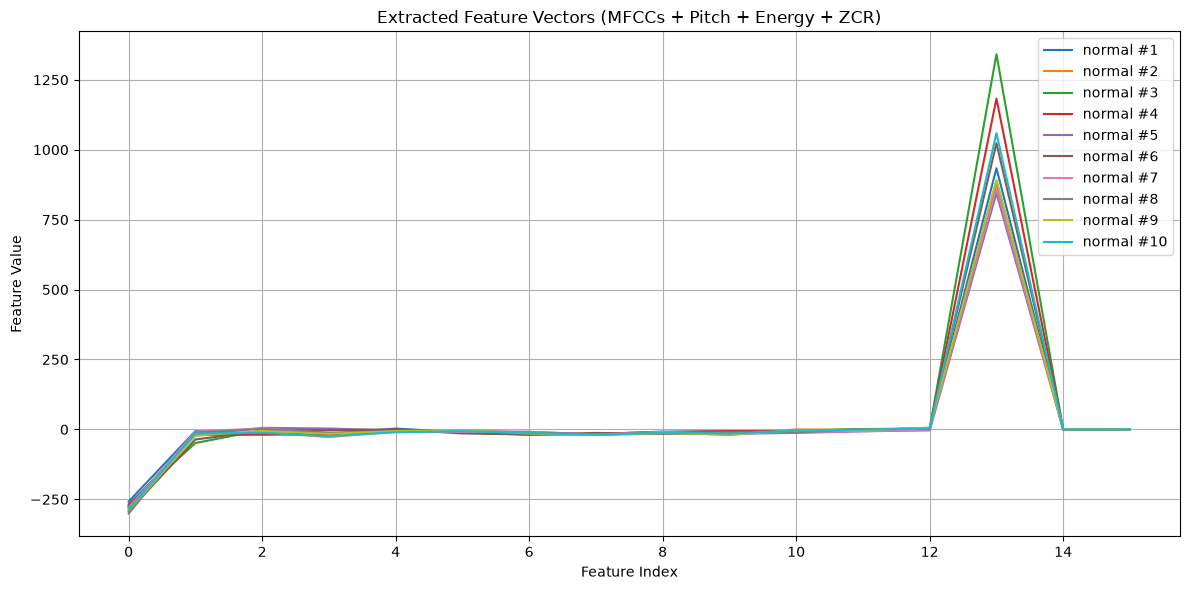

In [29]:
visualize_extracted_features(X, y)


# 🧠 Model Training & Evaluation

In [30]:

import numpy as np

X = np.array(X)
y = np.array(y)

print("Feature shape:", X.shape)
print("Labels shape:", y.shape)






Feature shape: (800, 16)
Labels shape: (800,)


# ***TRAIN TEST SPLIT***

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [33]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=10,
    min_samples_split=10,
    max_features=0.5,
    random_state=42
)

model.fit(X_train_scaled, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: 

# ***K FOLD CROSS VALIDATION***

In [34]:

# Define Stratified K-Fold
from sklearn.model_selection import StratifiedKFold, cross_val_score
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Perform cross-validation
cv_scores = cross_val_score(model, X, y, cv=skf, scoring='accuracy')

# Results
print("Cross-validation accuracies:", cv_scores)
print("Average accuracy:", np.mean(cv_scores))

Cross-validation accuracies: [0.94375 0.91875 0.95625 0.89375 0.98125]
Average accuracy: 0.93875


# ***TRAINING AND TESTING ACCURACY***

In [35]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Predictions
y_pred = model.predict(X_test_scaled)

# Accuracy
print(f"Train Accuracy: {model.score(X_train_scaled, y_train):.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")


Train Accuracy: 0.9594
Test Accuracy: 0.9437


# ***Classification Report***

In [36]:
# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["normal", "depressed"]))



Classification Report:
              precision    recall  f1-score   support

      normal       0.96      0.93      0.94        80
   depressed       0.93      0.96      0.94        80

    accuracy                           0.94       160
   macro avg       0.94      0.94      0.94       160
weighted avg       0.94      0.94      0.94       160



# ***Confusion Matrix***

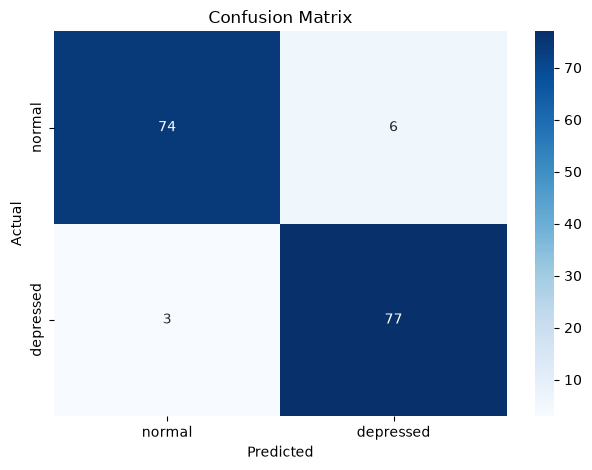

In [37]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["normal", "depressed"], yticklabels=["normal", "depressed"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# ***LEARNING CURVE***

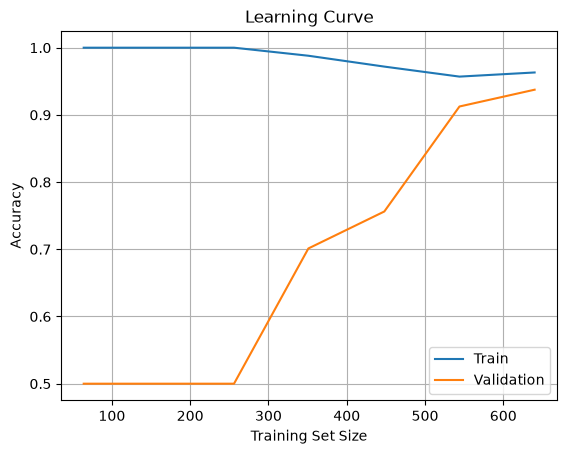

In [38]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(
    model, X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 7)
)
plt.plot(train_sizes, train_scores.mean(axis=1), label='Train')
plt.plot(train_sizes, test_scores.mean(axis=1), label='Validation')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()
# Generate learning curve data
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X_train_scaled,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),  # 10 points between 10% and 100% of training data
    cv=5,                                   # 5-fold cross-validation
    scoring='accuracy',
    n_jobs=-1                               # use all CPU cores
)

# ***ROC CURVE***

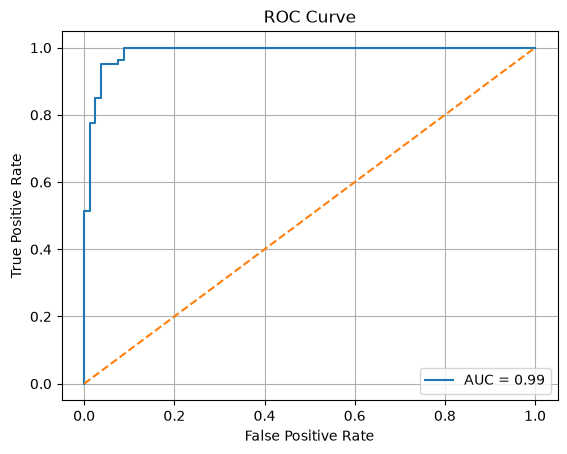

In [39]:
from sklearn.metrics import roc_curve, auc

# === ROC-AUC CURVE ===
# Check if the number of unique classes in the test set is 2 for ROC-AUC
if len(np.unique(y_test)) == 2:
    # Get the probability of the positive class (class 1, 'depressed' in this case based on label encoding)
    y_probs = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_probs)
    roc_auc = auc(fpr, tpr)

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.title("ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("ROC-AUC curve is only applicable for binary classification.")

# *** CROSS VALIDATION SCORE***

In [40]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
import numpy as np

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
print("Validation Accuracy (CV): %.4f ± %.4f" % (scores.mean(), scores.std()))

Validation Accuracy (CV): 0.9387 ± 0.0302


# ***CONVERSION IN PKL FILE ***

---



In [41]:
import joblib

# model, scaler, and label encoder must already be trained/fitted
# Example: model.fit(...), scaler.fit(...), le.fit(...)

# Save model
joblib.dump(model, "rf_model.pkl")

# Save scaler
joblib.dump(scaler, "scaler.pkl")

# Save label encoder
# joblib.dump(le, "label_encoder.pkl")

print("✅ Saved: rf_model.pkl, scaler.pkl")

✅ Saved: rf_model.pkl, scaler.pkl


# ***VALIDATION CURVE***

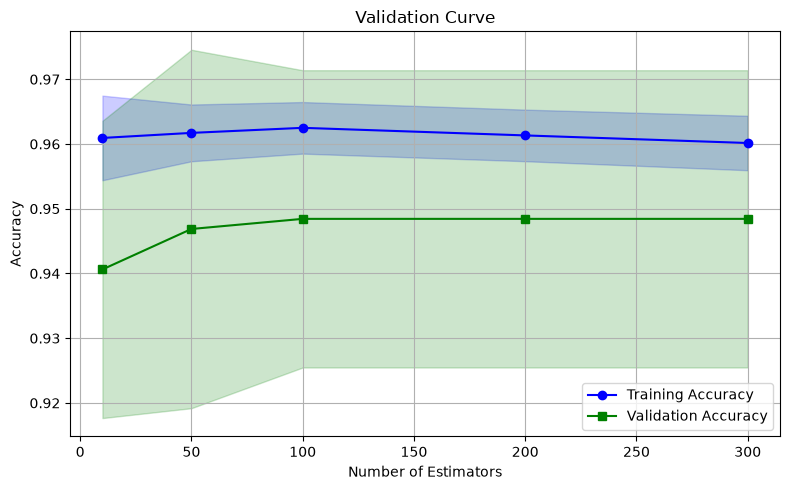

In [42]:
from sklearn.model_selection import validation_curve
import numpy as np
import matplotlib.pyplot as plt

# Example: Tuning 'n_estimators' for RandomForestClassifier
param_range = [10, 50, 100, 200, 300]

# Compute training and validation scores
train_scores, val_scores = validation_curve(
    estimator=model,
    X=X_train_scaled,
    y=y_train,
    param_name="n_estimators",      # Change this to your model's hyperparameter
    param_range=param_range,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Calculate mean and std
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(param_range, train_mean, label="Training Accuracy", color="blue", marker='o')
plt.fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.2, color="blue")

plt.plot(param_range, val_mean, label="Validation Accuracy", color="green", marker='s')
plt.fill_between(param_range, val_mean - val_std, val_mean + val_std, alpha=0.2, color="green")

plt.title("Validation Curve")
plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.legend(loc="best")
plt.grid(True)
plt.tight_layout()
plt.show()



# ***TRAINING VS TESTING***

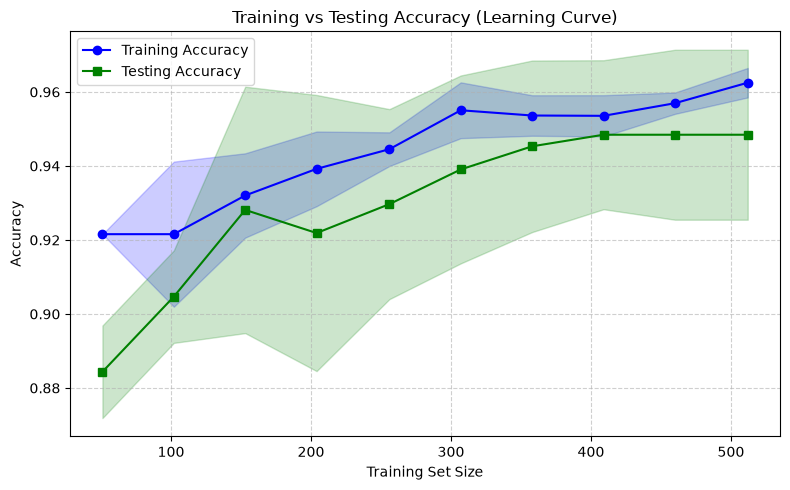

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve


# Generate learning curve data
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X_train_scaled,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),  # 10 points between 10% and 100% of training data
    cv=5,                                   # 5-fold cross-validation
    scoring='accuracy',
    n_jobs=-1                               # use all CPU cores
)

# Calculate means and std‑devs
train_mean = np.mean(train_scores, axis=1)
train_std  = np.std(train_scores,  axis=1)
test_mean  = np.mean(test_scores,  axis=1)
test_std   = np.std(test_scores,   axis=1)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, label='Training Accuracy', marker='o', color='blue')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                 alpha=0.2, color='blue')

plt.plot(train_sizes, test_mean, label='Testing Accuracy', marker='s', color='green')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std,
                 alpha=0.2, color='green')

plt.title('Training vs Testing Accuracy (Learning Curve)')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# ***FEATURE VISUALIZATION***

In [44]:
feature_names = [f'mfcc_{i+1}' for i in range(13)] + ['pitch', 'energy', 'zcr']


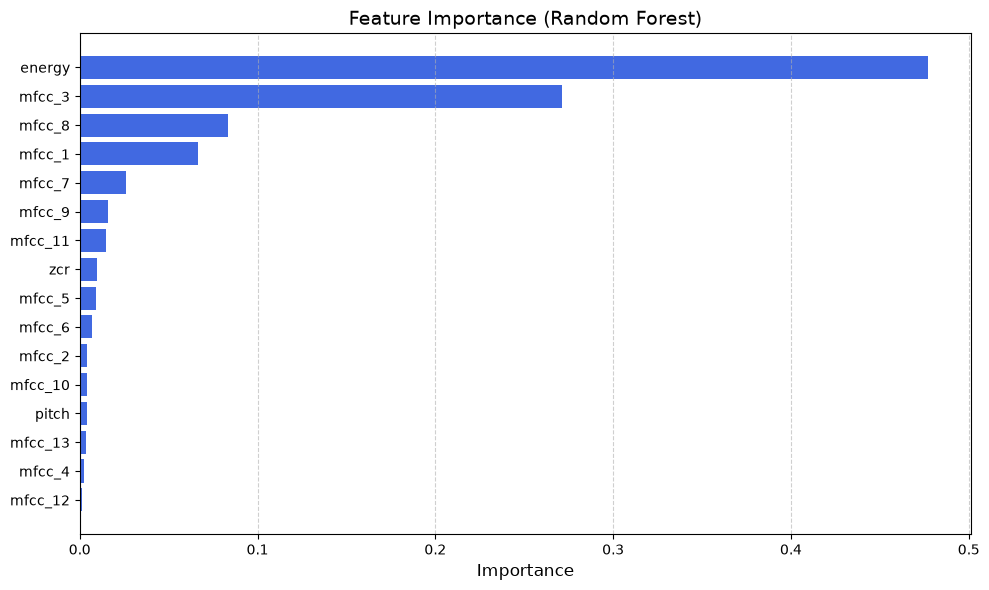

In [45]:
# Get feature importances from the trained model
importances = model.feature_importances_

# Sort by importance
sorted_idx = np.argsort(importances)
plt.figure(figsize=(10, 6))
plt.barh(np.array(feature_names)[sorted_idx], importances[sorted_idx], color='royalblue')
plt.xlabel("Importance", fontsize=12)
plt.title("Feature Importance (Random Forest)", fontsize=14)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()